# 01 · Exploratory data analysis (tasks 2–7)
PneumoniaMNIST: 28×28 grayscale pediatric chest X-rays, binary normal vs. pneumonia.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

from config import CLASS_NAMES, FIG_DIR, SEED, set_seeds
from src.data import load_splits

set_seeds()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
data, label_names = load_splits()
print("TFDS label names:", label_names)

TFDS label names: [np.str_('Normal'), np.str_('Pneumonia')]


## Task 2 · Split sizes, class counts, label mapping

In [2]:
rows = []
for split, (X, y) in data.items():
    counts = np.bincount(y, minlength=2)
    rows.append({"split": split, "n": len(y), "shape": X.shape[1:], "dtype": X.dtype,
                 "label_0": counts[0], "label_1": counts[1], "pct_label_1": round(100 * counts[1] / len(y), 1)})
summary = pd.DataFrame(rows)
summary

,split,n,shape,dtype,label_0,label_1,pct_label_1
0,train,4708,"(28, 28, 1)",uint8,1214,3494,74.2
1,val,524,"(28, 28, 1)",uint8,135,389,74.2
2,test,624,"(28, 28, 1)",uint8,234,390,62.5


Label mapping check: the majority class should be pneumonia, so label 1 = pneumonia if `pct_label_1` > 50.

In [3]:
assert summary.loc[summary.split == "train", "pct_label_1"].item() > 50, "label 1 is not the majority class"
print("Mapping used throughout:", CLASS_NAMES)

Mapping used throughout: {0: 'normal', 1: 'pneumonia'}


**Findings.** TFDS names the labels `['Normal', 'Pneumonia']`, so 0 = normal and 1 = pneumonia. Train and
validation are 74.2% pneumonia; test is 62.5%. "Always predict pneumonia" would therefore score 74% accuracy
on validation but only 62.5% on test, which is why we rely on AUC, sensitivity and specificity, and use class weights.

## Task 3 · Class counts per split (Figure 1)

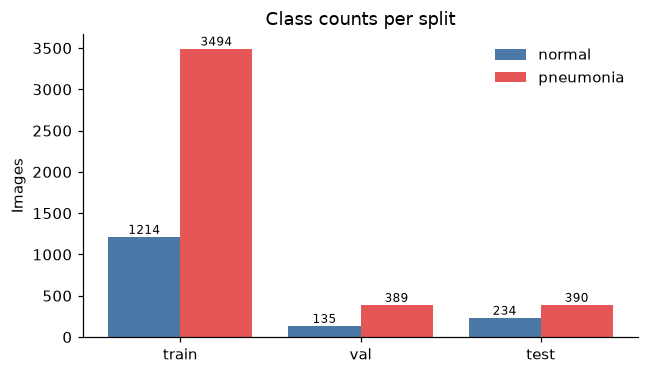

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(len(summary))
ax.bar(x - 0.2, summary.label_0, 0.4, label="normal", color="#4C78A8")
ax.bar(x + 0.2, summary.label_1, 0.4, label="pneumonia", color="#E45756")
for i, r in summary.iterrows():
    ax.text(i - 0.2, r.label_0, r.label_0, ha="center", va="bottom", fontsize=8)
    ax.text(i + 0.2, r.label_1, r.label_1, ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, summary.split)
ax.set_ylabel("Images")
ax.set_title("Class counts per split")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_class_counts.png")
plt.show()

## Task 4 · Sample grid (Figure 2)

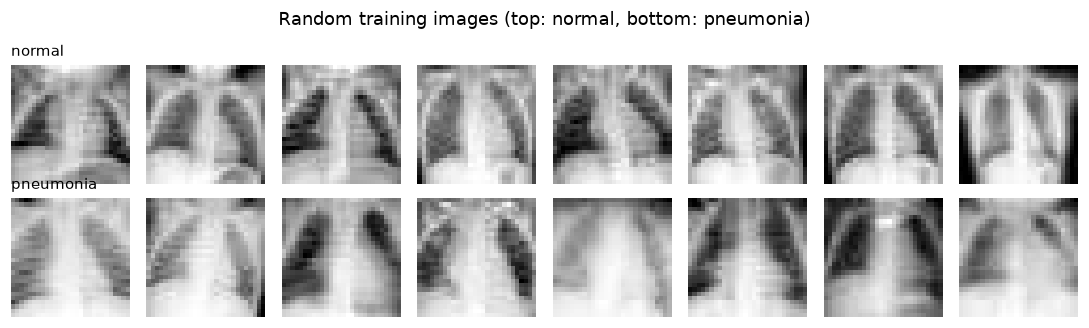

In [5]:
X_tr, y_tr = data["train"]
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for row, label in enumerate([0, 1]):
    idx = rng.choice(np.where(y_tr == label)[0], 8, replace=False)
    for col, i in enumerate(idx):
        axes[row, col].imshow(X_tr[i, ..., 0], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(CLASS_NAMES[label], loc="left", fontsize=10)
fig.suptitle("Random training images (top: normal, bottom: pneumonia)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_sample_grid.png")
plt.show()

## Task 5 · Mean image per class and difference (Figure 3)

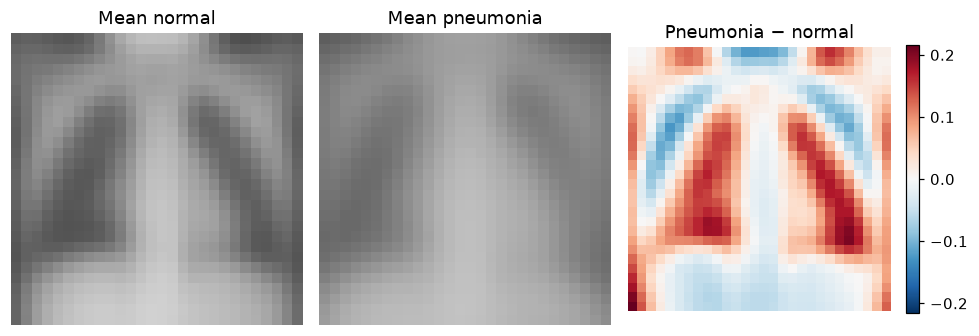

Mean pixel value: normal 0.549, pneumonia 0.580


In [6]:
Xf = X_tr[..., 0].astype(np.float32) / 255
mean_n, mean_p = Xf[y_tr == 0].mean(0), Xf[y_tr == 1].mean(0)
diff = mean_p - mean_n
lim = np.abs(diff).max()
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
axes[0].imshow(mean_n, cmap="gray", vmin=0, vmax=1); axes[0].set_title("Mean normal")
axes[1].imshow(mean_p, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Mean pneumonia")
im = axes[2].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim); axes[2].set_title("Pneumonia − normal")
for a in axes:
    a.axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_mean_images.png")
plt.show()
print(f"Mean pixel value: normal {mean_n.mean():.3f}, pneumonia {mean_p.mean():.3f}")

**Findings.** The difference image is strongly positive (red) inside both lung fields: pneumonia lungs are
brighter on average, consistent with opacities (fluid or consolidation) filling normally dark, air-filled lung.
Normal images show sharper lung borders, so the edges appear blue.

## Task 6 · Intensity histograms (Figure 4) and PCA scatter (Figure 5)

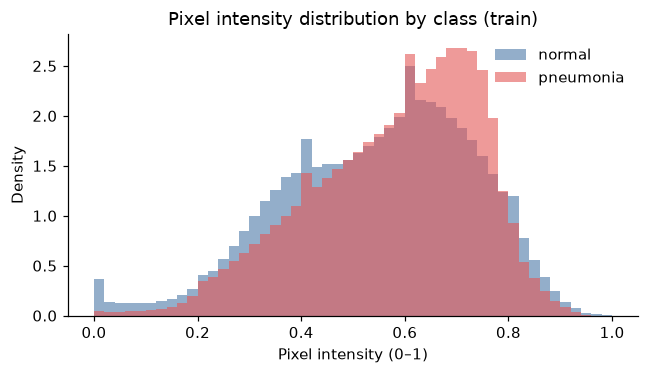

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(0, 1, 51)
ax.hist(Xf[y_tr == 0].ravel(), bins, density=True, alpha=0.6, label="normal", color="#4C78A8")
ax.hist(Xf[y_tr == 1].ravel(), bins, density=True, alpha=0.6, label="pneumonia", color="#E45756")
ax.set_xlabel("Pixel intensity (0–1)")
ax.set_ylabel("Density")
ax.set_title("Pixel intensity distribution by class (train)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_intensity_hist.png")
plt.show()

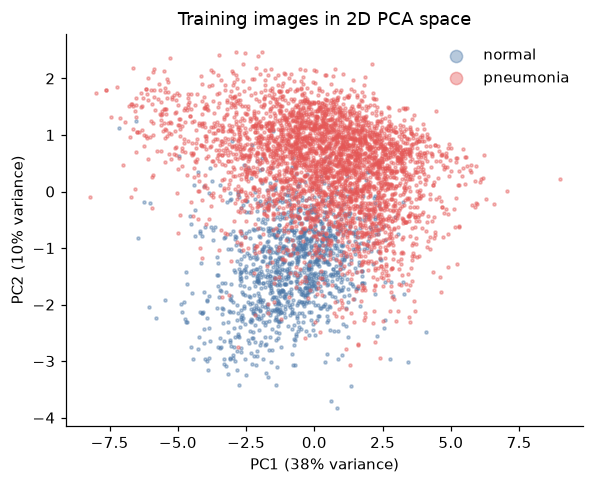

In [8]:
pca = PCA(n_components=2, random_state=SEED).fit(Xf.reshape(len(Xf), -1))
Z = pca.transform(Xf.reshape(len(Xf), -1))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for label, color in [(0, "#4C78A8"), (1, "#E45756")]:
    m = y_tr == label
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, color=color, label=CLASS_NAMES[label])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.set_title("Training images in 2D PCA space")
ax.legend(frameon=False, markerscale=4)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_pca_scatter.png")
plt.show()

**Findings.** The classes separate mostly along PC2, but with a clear overlap zone. A linear model on pixels
should already do well, and the overlap is where non-linear models and CNNs have room to improve.

## Task 7 · Duplicates and train/test brightness shift (Figure 6)

In [9]:
hashes = {s: [hashlib.md5(img.tobytes()).hexdigest() for img in X] for s, (X, _) in data.items()}
for s, h in hashes.items():
    print(f"{s}: {len(h) - len(set(h))} exact duplicate images within split")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} ∩ {b}: {len(set(hashes[a]) & set(hashes[b]))} identical images shared")

train: 18 exact duplicate images within split
val: 0 exact duplicate images within split
test: 3 exact duplicate images within split
train ∩ val: 8 identical images shared
train ∩ test: 0 identical images shared
val ∩ test: 0 identical images shared


**Findings.** There are a few exact duplicates (18 within train, 3 within test), and 8 images appear in both
train and validation. That is about 1.5% of validation, a small leak that could slightly inflate validation
scores. Test shares no images with train or validation. We keep the official splits for comparability and
report this as a limitation.

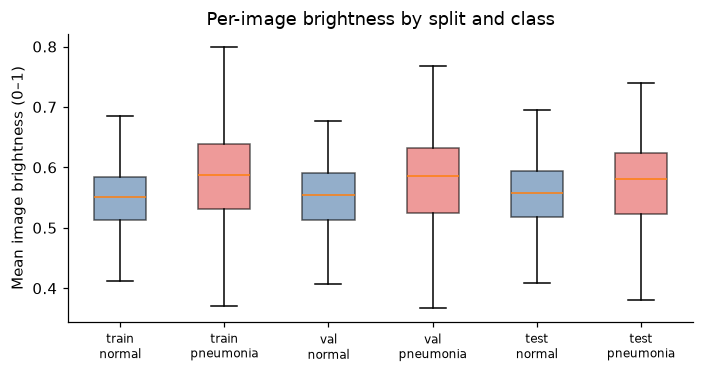

mean    std
split class                  
test  normal     0.555  0.066
      pneumonia  0.569  0.074
train normal     0.549  0.054
      pneumonia  0.580  0.084
val   normal     0.551  0.056
      pneumonia  0.575  0.084

In [10]:
bright = pd.DataFrame(
    [{"split": s, "class": CLASS_NAMES[int(l)], "mean_brightness": img.mean() / 255}
     for s, (X, y) in data.items() for img, l in zip(X, y)]
)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
groups = [(s, c) for s in ["train", "val", "test"] for c in ["normal", "pneumonia"]]
vals = [bright.query("split == @s and `class` == @c").mean_brightness for s, c in groups]
bp = ax.boxplot(vals, patch_artist=True, showfliers=False)
for patch, (_, c) in zip(bp["boxes"], groups):
    patch.set_facecolor("#4C78A8" if c == "normal" else "#E45756")
    patch.set_alpha(0.6)
ax.set_xticks(range(1, 7), [f"{s}\n{c}" for s, c in groups], fontsize=8)
ax.set_ylabel("Mean image brightness (0–1)")
ax.set_title("Per-image brightness by split and class")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_brightness_by_split.png")
plt.show()
bright.groupby(["split", "class"]).mean_brightness.agg(["mean", "std"]).round(3)

**Findings.** Pneumonia images are brighter and more variable than normal ones in every split. The gap is
smaller on test (pneumonia 0.569 vs 0.580 in train). Together with test's different class balance, this mild
shift suggests test scores may come in below validation scores.